In [1]:
from hexgrid import HexCoord, HexGrid, build_obstacle_map, VelocityState, get_neighbors_at_radius, hdist
from hexstarrl import ReplayBuffer, ExperienceCollector, EnvironmentStore, HUNetTDTrainer, HUNetStateEncoder, ValueNetwork_HUNet, RLState, HexUNetHeuristic

from hexstar import HStarProblem, HStarSearch, h_cost_travel_time_euclidean, h_cost_travel_time_manhattan, construct_full_solution, BidHStarSearch, calculate_path_smoothness, travel_time_euclidean
from hexplot import plot_hex_grid_2

from tqdm.auto import tqdm

from dataclasses import dataclass

import random
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from collections import defaultdict
import torch.nn as nn


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


Device: cuda


In [3]:
from pathlib import Path


# ============================================================
# RL SAVE / CHECKPOINT FILES
# ============================================================

RL_SAVE_DIR = Path(
    "rl_checkpoints"
)

RL_SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Environment data
# ------------------------------------------------------------

ENVIRONMENT_STORE_FILE = (
    RL_SAVE_DIR
    / "environment_store.pkl"
)


# ------------------------------------------------------------
# Full trainer checkpoint
#
# Includes:
#   online model
#   target model
#   optimizer
#   training step
#   trainer hyperparameters
# ------------------------------------------------------------

TRAINER_CHECKPOINT_FILE = (
    RL_SAVE_DIR
    / "hunet_td_trainer.pt"
)


# ------------------------------------------------------------
# Value-network weights only
#
# Useful for inference / HexUNet heuristic evaluation without
# restoring optimizer or target-network state.
# ------------------------------------------------------------

VALUE_NETWORK_WEIGHTS_FILE = (
    RL_SAVE_DIR
    / "hunet_value_network.pt"
)


# ------------------------------------------------------------
# Optional experiment / benchmark output
# ------------------------------------------------------------

BENCHMARKS_FILE = (
    RL_SAVE_DIR
    / "training_benchmarks.pkl"
)


print("Environment store: ", ENVIRONMENT_STORE_FILE)
print("Trainer checkpoint:", TRAINER_CHECKPOINT_FILE)
print("Network weights:   ", VALUE_NETWORK_WEIGHTS_FILE)
print("Benchmarks:        ", BENCHMARKS_FILE)

Environment store:  rl_checkpoints/environment_store.pkl
Trainer checkpoint: rl_checkpoints/hunet_td_trainer.pt
Network weights:    rl_checkpoints/hunet_value_network.pt
Benchmarks:         rl_checkpoints/training_benchmarks.pkl


In [4]:
# ============================================================
# H* PROBLEM / SEARCH DISTRIBUTION
# ============================================================

NUM_RUNS = 1
FIRST_RUN = 0

CENTER = HexCoord(0, 0)
SAFE_RADIUS = 8
HEX_SIZE = 0.1


map_type_config = {
    "random_n": {
        "obs_density_min": 0.10,
        "obs_density_max": 0.40,
    },

    "clustered_n": {
        "obs_density_min": 0.10,
        "obs_density_max": 0.40,
        "min_cluster_size": 20,
        "max_cluster_size": 200,
        "exclude_radius": SAFE_RADIUS,
    },
}


search_param_grid = {
    "map_type": [
        "random_n",
        "clustered_n",
    ],

    "search_type": [
        "unidirectional",
    ],

    "heuristic_name": [
        "manhattan",
        "euclidean",
    ],

    "radius": [
        15,
        25,
        35,
    ],

    "ay_window_ms": [
        3,
        7,
    ],

    "jps_horizon": [
        1,
        3,
        5,
        10,
        None,
    ],

    "n_step": [
        1,
        2,
        5,
    ],

    "a_min": [2],
    "a_max": [1],

    "join_tolerance": [50],
    "state_key_mode": ["location"],
}

In [5]:
# ============================================================
# RL MODEL PARAMETERS
# ============================================================

spatial_channels = 16
state_features = 5


# ============================================================
# REPLAY BUFFER PARAMETERS
# ============================================================

replay_capacity = 2_000_000
solution_fraction = 0.20


# ============================================================
# RL TRAINING PARAMETERS
# ============================================================

learning_rate = 1e-3

gamma = 1.0

target_update_every = 100

solution_weight = 0.80
nonterminal_weight = 0.20

batch_size = 16

training_steps_per_search = 5

In [6]:
def random_start_goal(center, radius, min_distance_ratio=0.5, seed=0):
    random.seed(seed)
    while True:
        q1 = random.randint(-radius + 1, radius - 1)
        r1 = random.randint(
            max(-radius + 1, -q1 - radius + 1),
            min(radius - 1, -q1 + radius - 1)
        )

        q2 = random.randint(-radius + 1, radius - 1)
        r2 = random.randint(
            max(-radius + 1, -q2 - radius + 1),
            min(radius - 1, -q2 + radius - 1)
        )

        start = HexCoord(center.q + q1, center.r + r1)
        goal = HexCoord(center.q + q2, center.r + r2)

        distance = (
            abs(start.q - goal.q)
            + abs(start.r - goal.r)
            + abs((start.q + start.r) - (goal.q + goal.r))
        ) // 2

        if distance >= radius * min_distance_ratio:
            return start, goal

In [7]:
# ============================================================
# INITIALIZE RL OBJECTS
# ============================================================

environment_store = EnvironmentStore()

replay_buffer = ReplayBuffer(
    capacity=replay_capacity,
    solution_fraction=solution_fraction,
)

experience_collector = ExperienceCollector(
    replay_buffer=replay_buffer,
    environment_store=environment_store,
)

encoder = HUNetStateEncoder()

value_network = ValueNetwork_HUNet(
    encoder=encoder,
    spatial_channels=spatial_channels,
    state_features=state_features,
)

h_hexunet = HexUNetHeuristic(
    model=value_network,
)

trainer = HUNetTDTrainer(
    model=value_network,
    replay_buffer=replay_buffer,
    environment_store=environment_store,
    learning_rate=learning_rate,
    gamma=gamma,
    target_update_every=target_update_every,
    solution_weight=solution_weight,
    nonterminal_weight=nonterminal_weight,
)


# ============================================================
# INITIAL STATE
# ============================================================

print("Environment count:", len(environment_store))
print("Replay buffer size:", len(replay_buffer))
print("Grounded samples:", replay_buffer.solution_size)
print("Nonterminal samples:", replay_buffer.nonterminal_size)
print("Trainer steps:", trainer.training_steps)

Environment count: 0
Replay buffer size: 0
Grounded samples: 0
Nonterminal samples: 0
Trainer steps: 0


In [8]:
# ============================================================
# BUILD ONE H* PROBLEM
# ============================================================

seed = 0
environment_id = seed

# ------------------------------------------------------------
# Select problem parameters
# ------------------------------------------------------------

map_type = "clustered_n"

radius = 80

heuristic_name = "euclidean"

ay_window_ms = 7

jps_horizon = 5

n_step = 2

a_min = 2
a_max = 1

collision_radius = 0

# Start / goal velocity constraints
start_v = VelocityState(
    magnitude=0,
    direction=None,
)

goal_v = VelocityState(
    magnitude=0,
    direction=None,
)


# ------------------------------------------------------------
# Select heuristic
# ------------------------------------------------------------

heuristics = {
    "manhattan": h_cost_travel_time_manhattan,
    "euclidean": h_cost_travel_time_euclidean,
    "hexunet": h_hexunet,
}

heuristic = heuristics[
    heuristic_name
]


# ------------------------------------------------------------
# Map configuration
# ------------------------------------------------------------

map_config = map_type_config[
    map_type
]

rng = random.Random(
    seed
)

obs_density = rng.uniform(
    map_config["obs_density_min"],
    map_config["obs_density_max"],
)

n_obstacles = int(
    obs_density
    * 3
    * radius
    * (radius + 1)
)


# ------------------------------------------------------------
# Generate start / goal
# ------------------------------------------------------------

start, goal = random_start_goal(
    CENTER,
    radius,
    min_distance_ratio=0.60,
    seed=seed,
)


# ------------------------------------------------------------
# Build obstacle specification
# ------------------------------------------------------------

if map_type == "random_n":

    obstacle_spec = (
        "random_n",
        {
            "n": n_obstacles,
        },
    )

elif map_type == "clustered_n":

    obstacle_spec = (
        "clustered_n",
        {
            "n": n_obstacles,
            "min_cluster_size": (
                map_config["min_cluster_size"]
            ),
            "max_cluster_size": (
                map_config["max_cluster_size"]
            ),
            "exclude_radius": (
                map_config["exclude_radius"]
            ),
        },
    )

else:
    raise ValueError(
        f"Unsupported map_type: {map_type}"
    )


# ------------------------------------------------------------
# Generate obstacles
# ------------------------------------------------------------

obstacles = set(
    build_obstacle_map(
        center=CENTER,
        radius=radius,
        seed=seed,
        exclude=[
            start,
            goal,
        ],
        types=[
            obstacle_spec,
        ],
    ).keys()
)


# ------------------------------------------------------------
# Add blocked outer boundary
# ------------------------------------------------------------

obstacles.update(
    get_neighbors_at_radius(
        CENTER,
        radius,
    )
)


# ------------------------------------------------------------
# Build HexGrid
# ------------------------------------------------------------

hex_grid = HexGrid(
    hex_size=HEX_SIZE,
    obstacles=obstacles,
    center=CENTER,
    radius=radius,
)


# ------------------------------------------------------------
# Register environment for RL
# ------------------------------------------------------------

environment_store.add(
    environment_id,
    hex_grid,
)


# ------------------------------------------------------------
# Build HStarProblem
# ------------------------------------------------------------

problem = HStarProblem(
    grid=hex_grid,
    start=start,
    goal=goal,

    a_max=a_max,
    a_min=a_min,

    heuristic=heuristic,

    start_v=start_v,
    goal_v=goal_v,

    ay_window_ms=ay_window_ms,
    collision_radius=collision_radius,

    jps_horizon=jps_horizon,
    n_step=n_step,
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("Environment ID:", environment_id)
print("Map type:", map_type)
print("Radius:", radius)
print("Start:", start)
print("Goal:", goal)
print("Obstacle density:", obs_density)
print("Requested obstacles:", n_obstacles)
print("Actual obstacles:", len(obstacles))
print("Heuristic:", heuristic_name)
print("n_step:", n_step)
print("JPS horizon:", jps_horizon)

Environment ID: 0
Map type: clustered_n
Radius: 80
Start: HexCoord(q=19, r=28)
Goal: HexCoord(q=-69, r=23)
Obstacle density: 0.35332655545751446
Requested obstacles: 6868
Actual obstacles: 7206
Heuristic: euclidean
n_step: 2
JPS horizon: 5


In [9]:
plot_hex_grid_2(
    obstacles=obstacles,
    start=start,
    center=CENTER,
    radius=radius + 5,
    hex_size=HEX_SIZE,
    goal=goal,
    figsize=(5, 5),
    show_coords=False,
    linewidth=0,
    #path=solution_path,
    draw_axes=False,
    show_axis_legend=True,
    #save_path=str(save_path),
)

<Axes: >

Error in callback <function flush_figures at 0x7f7883e17e20> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [10]:
# ============================================================
# BUILD H* SEARCH
# ============================================================

import time 

hs = BidHStarSearch(
    problem=problem,

    # Search configuration
    bidirectional=False,

    # Experience collection
    experience_collector=experience_collector,
    environment_id=environment_id,

    # Persistent RL training
    online_trainer=trainer,
    online_batch_size=batch_size,
    online_training_steps=training_steps_per_search,
)

for i in range(60):
    start = time.time()
    fsolution = hs.search()
    f_soln_path = construct_full_solution(fsolution)
    print(f'{i}\t{time.time()-start}s')

0	157.12297010421753s
1	100.99729633331299s
2	97.93949890136719s
3	98.36113452911377s
4	98.41518712043762s
5	98.99361991882324s
6	99.62509274482727s
7	100.3576807975769s
8	97.68292808532715s
9	98.35844993591309s
10	98.86121678352356s
11	99.48103141784668s
12	101.38127517700195s
13	98.38264656066895s
14	97.04146838188171s
15	97.02653002738953s
16	97.10149550437927s
17	99.59325647354126s
18	97.39495921134949s
19	97.67608785629272s
20	100.55532121658325s
21	97.70220756530762s
22	97.44205594062805s
23	97.25381064414978s
24	97.64032435417175s
25	100.58634400367737s
26	97.88907837867737s
27	97.63294577598572s
28	97.88102698326111s
29	97.20549702644348s
30	97.94394493103027s
31	97.54209232330322s
32	97.10106897354126s
33	101.65919280052185s
34	97.30296444892883s
35	97.18860030174255s
36	97.99526238441467s
37	97.89818716049194s
38	97.14390230178833s
39	97.2406210899353s
40	98.6175971031189s
41	98.94825792312622s
42	100.07355189323425s
43	97.5132577419281s
44	97.7477536201477s
45	97.80353093147

<Axes: >

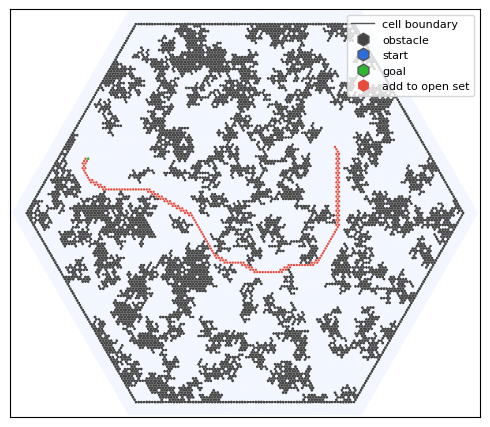

In [11]:
plot_hex_grid_2(
    obstacles=obstacles,
    start=start,
    center=CENTER,
    radius=radius + 5,
    hex_size=HEX_SIZE,
    goal=goal,
    figsize=(5, 5),
    show_coords=False,
    linewidth=0,
    path=f_soln_path,
    draw_axes=False,
    show_axis_legend=True,
    #save_path=str(save_path),
)

In [12]:
# ============================================================
# SAVE RL TRAINING STATE
# ============================================================

trainer.save_checkpoint(
    TRAINER_CHECKPOINT_FILE
)

trainer.save_weights(
    VALUE_NETWORK_WEIGHTS_FILE
)

environment_store.save(
    ENVIRONMENT_STORE_FILE
)

print("Saved RL state:")
print("  Trainer:     ", TRAINER_CHECKPOINT_FILE)
print("  Model:       ", VALUE_NETWORK_WEIGHTS_FILE)
print("  Environments:", ENVIRONMENT_STORE_FILE)

print()
print("Training steps:", trainer.training_steps)
print("Replay size:", len(replay_buffer))
print("Grounded samples:", replay_buffer.solution_size)
print("Nonterminal samples:", replay_buffer.nonterminal_size)
print("Environments:", len(environment_store))

Saved RL state:
  Trainer:      rl_checkpoints/hunet_td_trainer.pt
  Model:        rl_checkpoints/hunet_value_network.pt
  Environments: rl_checkpoints/environment_store.pkl

Training steps: 300
Replay size: 1601018
Grounded samples: 1018
Nonterminal samples: 1600000
Environments: 1


In [ ]:
benchmarks = hs.get_benchmarks()

benchmarks["online_last_metrics"]


In [ ]:
import pickle

with open(
    BENCHMARKS_FILE,
    "wb",
) as f:
    pickle.dump(
        benchmarks,
        f,
    )

In [ ]:
import matplotlib.pyplot as plt


def plot_online_training(benchmarks):
    """Plot online value-network training metrics."""

    history = benchmarks.get(
        "online_training_history",
        [],
    )

    if not history:
        print("No online training history.")
        return

    steps = range(
        1,
        len(history) + 1,
    )

    loss = [
        m["loss"]
        for m in history
    ]

    solution_loss = [
        m["grounded_loss"]
        for m in history
    ]

    nonterminal_loss = [
        m["nonterminal_loss"]
        for m in history
    ]

    solution_samples = [
        m["grounded_samples"]
        for m in history
    ]

    nonterminal_samples = [
        m["nonterminal_samples"]
        for m in history
    ]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4),
    )

    # ---------------------------------------------------------
    # Loss
    # ---------------------------------------------------------

    axes[0].plot(
        steps,
        loss,
        label="Overall Loss",
    )

    axes[0].plot(
        steps,
        solution_loss,
        label="Solution Loss",
    )

    axes[0].plot(
        steps,
        nonterminal_loss,
        label="Nonterminal Loss",
    )

    axes[0].set_xlabel(
        "Training Step"
    )

    axes[0].set_ylabel(
        "MSE Loss"
    )

    axes[0].set_title(
        "Online Training Loss"
    )

    axes[0].legend()

    # ---------------------------------------------------------
    # Samples contributing to training
    # ---------------------------------------------------------

    axes[1].plot(
        steps,
        solution_samples,
        label="Solution Samples",
    )

    axes[1].plot(
        steps,
        nonterminal_samples,
        label="Nonterminal Samples",
    )

    axes[1].set_xlabel(
        "Training Step"
    )

    axes[1].set_ylabel(
        "Samples"
    )

    axes[1].set_title(
        "Training Sample Composition"
    )

    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
plot_online_training(benchmarks)

In [ ]:
nope = {
    'open_set_sizes',
    'closed_set_sizes',
    'forward_open_set_sizes',
    'forward_closed_set_sizes',
}

In [ ]:
{print(k,v) for k,v in benchmarks.items() if k not in nope}

In [ ]:
def plot_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    velocity,
    center,
    radius,
    hex_size=1.0,
):
    value_network.eval()

    directions = (
        HexCoord( 1,  0),
        HexCoord( 1, -1),
        HexCoord( 0, -1),
        HexCoord(-1,  0),
        HexCoord(-1,  1),
        HexCoord( 0,  1),
    )

    direction_names = (
        "E",
        "SE",
        "SW",
        "W",
        "NW",
        "NE",
    )

    # Spatial context depends only on:
    # environment + goal
    #
    # So run HexUNet once.
    with torch.no_grad():
        context_map = value_network.encode_environment(
            environment,
            goal,
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 12),
    )

    axes = axes.flatten()

    obstacles = set(environment.obstacles)

    for ax, direction, direction_name in zip(
        axes,
        directions,
        direction_names,
    ):
        values = {}

        for q in range(
            center.q - radius,
            center.q + radius + 1,
        ):
            for r in range(
                center.r - radius,
                center.r + radius + 1,
            ):
                location = HexCoord(q, r)

                dq = q - center.q
                dr = r - center.r

                hex_distance = max(
                    abs(dq),
                    abs(dr),
                    abs(dq + dr),
                )

                if hex_distance > radius:
                    continue

                if location in obstacles:
                    continue

                state = RLState(
                    location=location,
                    velocity=VelocityState(
                        magnitude=velocity,
                        direction=direction,
                    ),
                )

                with torch.no_grad():
                    value = value_network.value(
                        problem=problem,
                        state=state,
                        goal=goal,
                        environment=environment,
                        context_map=context_map,
                    )

                values[location] = value.item()

        plot_hex_grid_2(
            obstacles=obstacles,
            path=values,
            start=problem.start,
            center=center,
            radius=radius,
            hex_size=hex_size,
            ax=ax,
        )

        ax.set_title(
            f"{direction_name}: {direction}"
        )

    plt.tight_layout()
    plt.show()

In [ ]:
s = replay_buffer.sample(100)[2]

goal = RLState(
    location=problem.goal,
    velocity=problem.goal_v,
)

plot_value_network_directions(
    value_network,
    problem,
    environment_store.get(s.environment_id),
    goal=goal,
    velocity=2,
    center=CENTER,
    radius=radius,
    hex_size=HEX_SIZE,
)